**Question 2**

(a) To plot the raw data from 0 to 800 seconds, we can index the data from np.loadtxt by finding the argument where the minimum difference from 0 and 800 was the smallest. The plot is shown below. The sampling rate $dt$ was found for part (c)

(b) Defined a Gaussian function gauss(t,H) taking argument $t_H$ (half duration), and plotted it for two different $t_H$ in a range of $\pm 3 \sigma$ where $\sigma$ was found by comparing equation (1) to known Gaussian format.

(c) Using numpy.convolve to take the convolution of the Gaussian at two half durations with the raw data - scaling it by $dt$ such that the integral is correctly approximated. The mode 'same' was used to make sure the output aligned along the same time series as the original raw data. It is observed that a longer half duration (i.e. a wider Gaussian) smoothed out the signal more. This makes sense because we convolve over a larger range/window, so higher frequencies cannot be resolved and get flattened out. 

AI: Used to find 'np.argmin' function

Collaborators: None

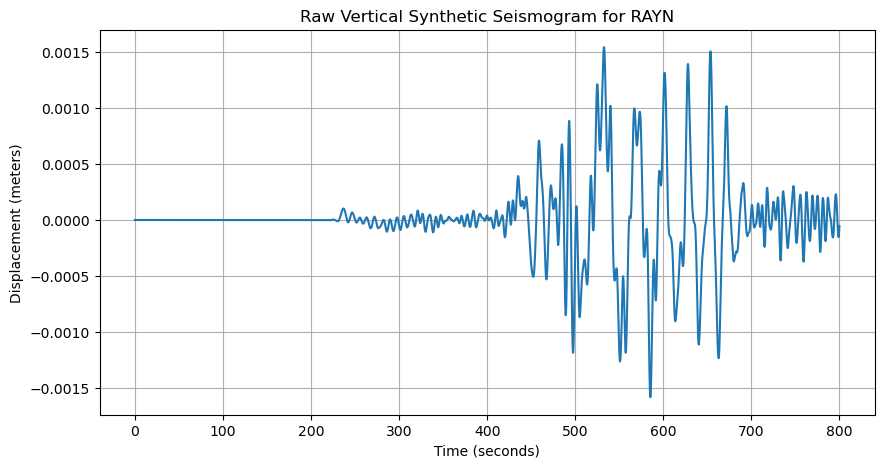

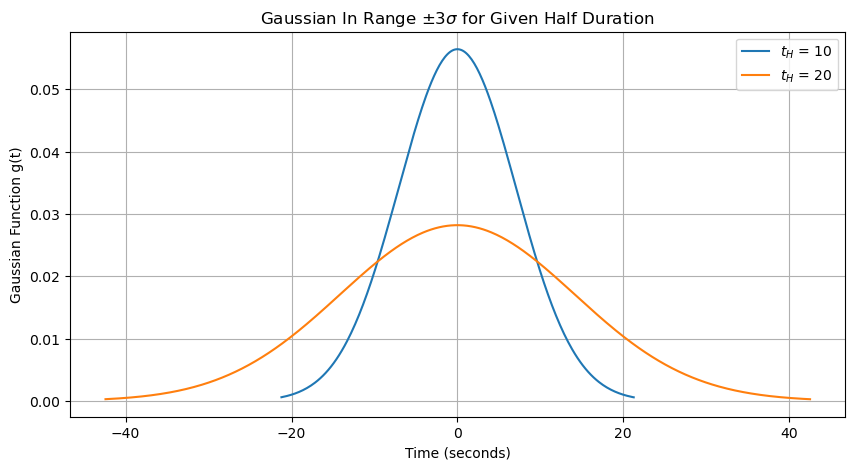

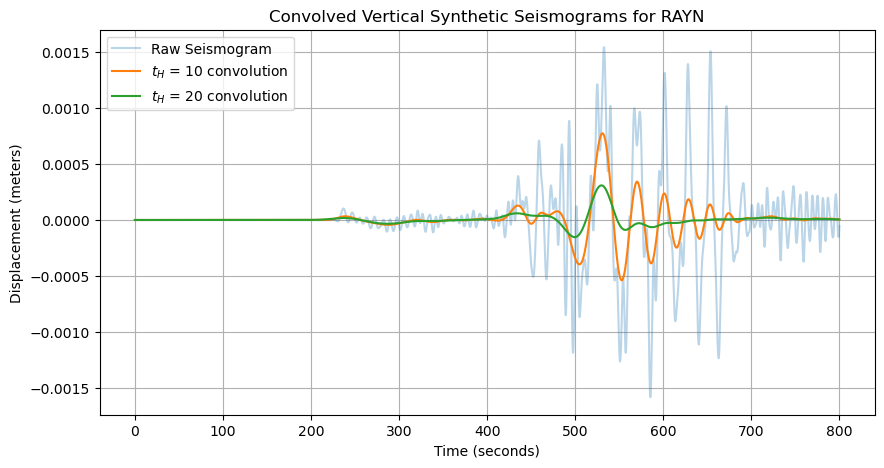

In [5]:
# Question 2: Numerical simulations of seismic wave propagation

# Import libraries
import numpy as np
import matplotlib.pyplot as plt

# Part a): Plot the raw data

# Extracting useful columns
data = np.loadtxt('RAYN.II.LHZ.sem')

time = data[:,0] # seconds
displacement = data[:,1] # meters

# Plot data from 0 to 800 seconds

# Find indices corresponding to 0 and 800 seconds

id_0 = np.argmin(np.abs(time))
id_800 = np.argmin(np.abs(time - 800))

t_raw = time[id_0:id_800 + 1]
x_raw = displacement[id_0:id_800+1]

# extract the rate of sampling for later

dt = np.mean([t_raw[i] - t_raw[i-1] for i in range(1, len(t_raw))])

plt.figure(figsize = (10,5))
plt.plot(t_raw, x_raw)
plt.xlabel('Time (seconds)')
plt.ylabel('Displacement (meters)')
plt.grid()
plt.title('Raw Vertical Synthetic Seismogram for RAYN')
plt.show()

# Part b): Plot the Gaussian functions

def gauss(t_H):
    """
    Returns an array of the gaussian g(t) for given t_H with mean zero, 
    for t between +/- 3*sigma sampled at same rate as the raw data. 
    Input: 
        t_H - half duration
    Output: 
        array of t values, array of g(t) for t in +/- 3*sigma
    """
    sigma = t_H/np.sqrt(2)
    t = np.arange(-3*sigma, 3*sigma + dt, dt)
    g = 1/(t_H*np.sqrt(np.pi)) * np.exp(-(t/t_H)**2)
    return t, g

plt.figure(figsize = (10,5))

for t_H in [10, 20]: # for two durations, plot the Gaussian
    t, g_t = gauss(t_H)
    
    plt.plot(t, g_t, label = rf'$t_H$ = {t_H}')

plt.xlabel('Time (seconds)')
plt.ylabel('Gaussian Function g(t)')
plt.title(r'Gaussian In Range $\pm 3 \sigma$ for Given Half Duration')
plt.legend()
plt.grid()
plt.show()

# Part c): Convolve the raw seisomgram with the Gaussian functions

plt.figure(figsize = (10,5))

plt.plot(t_raw, x_raw, alpha = 0.3, label = 'Raw Seismogram') # plot raw data

for t_H in [10, 20]:
    # generate the convolution with the same output length as x_raw
    t, g_t = gauss(t_H)
    y = np.convolve(x_raw, g_t, mode="same") * dt
    plt.plot(t_raw, y, label = rf'$t_H$ = {t_H} convolution')

plt.xlabel('Time (seconds)')
plt.ylabel('Displacement (meters)')
plt.grid()
plt.legend()
plt.title('Convolved Vertical Synthetic Seismograms for RAYN')
plt.show()